# Alanine scan figure

This notebook draws an alanine-scan figure for a peptide.

The top row is your original peptide. Each row below swaps one residue for alanine (shown as a black **A**) and is labelled with the substitution, for example D2A. Circles are coloured by amino acid class.

**How to use it**

1. In the next cell, type your peptide sequence and a name for it.
2. Choose **Runtime → Run all** (Colab) or **Run All** (Jupyter).
3. The figure appears below and is saved as a 600 dpi TIFF named after your peptide.

By default, glycine (G) and isoleucine (I) are not swapped to alanine, since the change is usually small. You can change this in `skip_residues`.

In [1]:
# ---- Your peptide ----
original_sequence = "VQAAQAGDTKPIEV"   # one-letter codes
peptide_name = "PN3"                    # used as the figure title and file name

# Residues that are NOT swapped to alanine.
# Use [] to scan every residue.
skip_residues = ["G", "I"]

# ---- Figure options ----
show_title = True
show_labels = True       # row labels like P1A, E2A ...
original_label = "WT"    # label for the original row, e.g. "WT" or "Native"
file_format = "tif"      # "tif" or "png"
dpi = 600

## Amino acid classes and colours

Each amino acid belongs to one class.

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

amino_acid_categories = {
    "polar":     ["N", "C", "Q", "S", "T", "Y"],
    "non-polar": ["A", "V", "L", "I", "M", "F", "P", "G", "W"],
    "anionic":   ["D", "E"],
    "cationic":  ["R", "H", "K"],
}

color_map = {
    "polar":     "#9467bd",   # purple
    "non-polar": "#ff7f0e",   # orange
    "anionic":   "#d62728",   # red
    "cationic":  "#2ca02c",   # green
}

def get_category(aa):
    for category, residues in amino_acid_categories.items():
        if aa.upper() in residues:
            return category
    raise ValueError(f"Unknown amino acid letter: {aa}")

## Make the alanine-scan sequences

In [3]:
original_sequence = original_sequence.strip().upper()
skip = {r.upper() for r in skip_residues} | {"A"}

# Lowercase "a" marks the residue that was swapped to alanine
Ala_scan_seq = [(original_sequence, original_label)]

for i, aa in enumerate(original_sequence):
    if aa in skip:
        continue
    new_sequence = list(original_sequence)
    new_sequence[i] = "a"
    Ala_scan_seq.append(("".join(new_sequence), f"{aa}{i + 1}A"))

for seq, label in Ala_scan_seq:
    print(f"{label:>8}  {seq}")

      WT  VQAAQAGDTKPIEV
     V1A  aQAAQAGDTKPIEV
     Q2A  VaAAQAGDTKPIEV
     Q5A  VQAAaAGDTKPIEV
     D8A  VQAAQAGaTKPIEV
     T9A  VQAAQAGDaKPIEV
    K10A  VQAAQAGDTaPIEV
    P11A  VQAAQAGDTKaIEV
    E13A  VQAAQAGDTKPIaV
    V14A  VQAAQAGDTKPIEa


## Draw and save the figure

Saved: PN3_ala_scan.tif


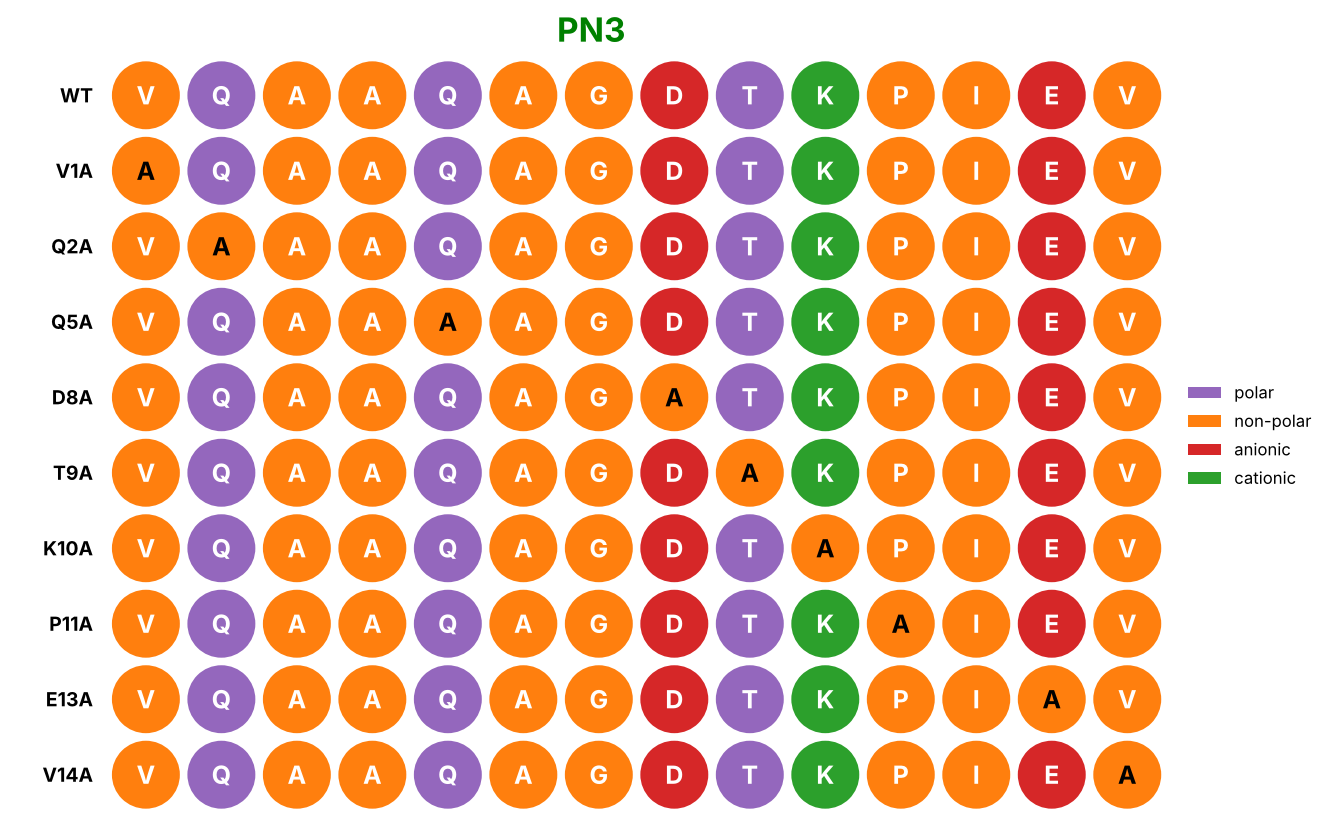

In [4]:
n_rows = len(Ala_scan_seq)
n_cols = len(original_sequence)

fig, ax = plt.subplots(figsize=(n_cols * 0.9 + 3, n_rows * 0.9 + 1))

for row, (seq, label) in enumerate(Ala_scan_seq):
    y = n_rows - row
    for col, aa in enumerate(seq):
        x = col + 1
        ax.add_patch(plt.Circle((x, y), 0.45, facecolor=color_map[get_category(aa)],
                                edgecolor="none"))
        if aa == "a":
            ax.text(x, y, "A", color="black", ha="center", va="center",
                    fontsize=18, weight="bold")
        else:
            ax.text(x, y, aa, color="white", ha="center", va="center",
                    fontsize=18, weight="bold")
    if show_labels and label:
        ax.text(0.3, y, label, ha="right", va="center", fontsize=14, weight="bold")

legend_elements = [Patch(facecolor=col, edgecolor="none", label=name)
                   for name, col in color_map.items()]
ax.legend(handles=legend_elements, loc="center left", bbox_to_anchor=(1, 0.5),
          frameon=False, fontsize=12)

if show_title and peptide_name:
    ax.set_title(peptide_name, fontsize=24, weight="bold", color="green")

ax.set_xlim(-0.8 if show_labels else 0.4, n_cols + 0.6)
ax.set_ylim(0.4, n_rows + 0.6)
ax.set_aspect("equal")
ax.axis("off")

file_name = f"{peptide_name or 'ala_scan'}_ala_scan.{file_format}"
plt.savefig(file_name, dpi=dpi, bbox_inches="tight")
print("Saved:", file_name)
plt.show()

## Download the figure (Colab only)

Run this cell to download the saved file to your computer. In Jupyter on your own computer, the file is already in the same folder as this notebook.

In [5]:
try:
    from google.colab import files
    files.download(file_name)
except ImportError:
    print("Not running in Colab. The file is saved next to this notebook:", file_name)

Not running in Colab. The file is saved next to this notebook: PN3_ala_scan.tif
